# Qui utilise mon appli ? Identifier un utilisateur à partir de ses traces

Objectif : retrouver lequel des 247 utilisateurs de Copilote a produit une session, à partir des actions qu'elle contient. Métrique du challenge : F1 moyen (on suit le **F1 macro**).

Le fil du notebook : explorer les données, construire un premier modèle sur des features manuelles, comprendre ses limites, puis passer à une représentation textuelle des sessions (TF-IDF + SVM linéaire).

## 1. Chargement des données

In [1]:
import re
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

MARQUEUR = re.compile(r"t\d+")

def lire_sessions(chemin, avec_label):
    """Une ligne par session : utilisateur (train seulement), navigateur, actions, durée (dernier marqueur tXX)."""
    lignes = []
    with open(chemin, encoding="utf-8") as f:
        for ligne in f:
            champs = ligne.rstrip("\n").split(",")
            util = champs.pop(0) if avec_label else None
            marqueurs = [int(e[1:]) for e in champs[1:] if MARQUEUR.fullmatch(e)]
            actions = [e for e in champs[1:] if not MARQUEUR.fullmatch(e)]
            lignes.append({"util": util, "navigateur": champs[0], "actions": actions,
                           "nb_actions": len(actions), "duree": marqueurs[-1] if marqueurs else 0})
    return pd.DataFrame(lignes)

train = lire_sessions("data/train.csv", avec_label=True)
test = lire_sessions("data/test.csv", avec_label=False)
print(len(train), "sessions d'entraînement,", len(test), "sessions de test")
train[["util", "navigateur", "nb_actions", "duree"]].head()

3279 sessions d'entraînement, 324 sessions de test


,util,navigateur,nb_actions,duree
0,nuh,Firefox,2514,2905
1,muz,Google Chrome,90,230
2,zrx,Microsoft Edge,608,750
3,pou,Firefox,886,1445
4,ald,Google Chrome,173,275


Une action a la forme `Type(écran)<configuration>$chaîne$`, avec un `1` final si l'utilisateur est en modification dans la fiche. Exemple :

In [2]:
train["actions"][1][:6]

["Création d'un écran(infologic.core.gui.controllers.BlankController)",
 "Création d'un écran(infologic.core.gui.controllers.nested.InputFormNestedWindow)",
 'Sélection d’un onglet(infologic.orga.modules.OR_FICHIERTRAVAIL.InstanceForm)<TELEM_MINIMAL>',
 "Exécution d'un bouton",
 'Sélection d’un onglet',
 "Exécution d'un bouton"]

## 2. Première analyse

findfont: Failed to find font weight normal for Lucida Grande, now using 500.


             count   mean     std  min    25%    50%    75%      max
nb_actions  3279.0  692.0  1006.0  0.0  153.0  340.0  818.0  11977.0
duree       3279.0  752.0  1006.0  5.0  185.0  395.0  945.0  11790.0

sessions par utilisateur : {'count': 247.0, 'mean': 13.3, 'std': 8.9, 'min': 4.0, '25%': 7.0, '50%': 12.0, '75%': 16.0, 'max': 75.0}


findfont: Failed to find font weight normal for Lucida Grande, now using 500.


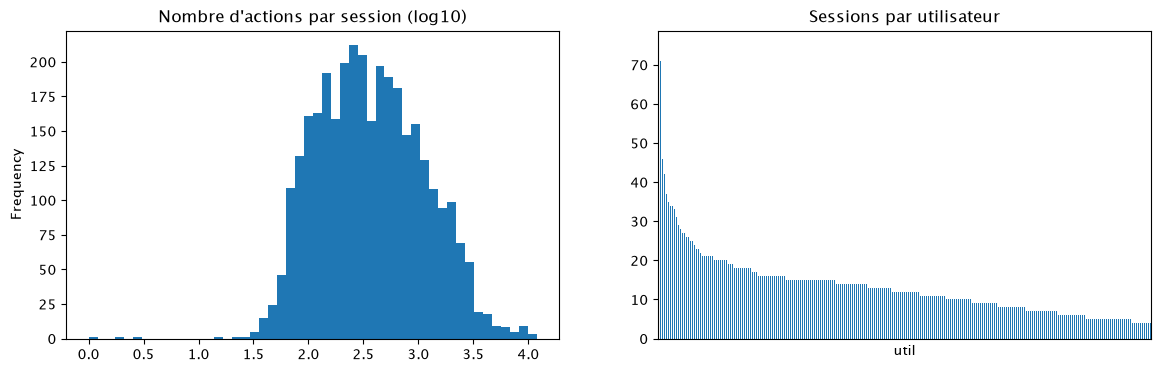

In [3]:
sessions_par_util = train["util"].value_counts()
print(train[["nb_actions", "duree"]].describe().round(0).T)
print("\nsessions par utilisateur :", sessions_par_util.describe().round(1).to_dict())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
np.log10(train["nb_actions"] + 1).plot.hist(bins=50, ax=ax1, title="Nombre d'actions par session (log10)")
sessions_par_util.plot.bar(ax=ax2, xticks=[], title="Sessions par utilisateur")
plt.show()

In [4]:
print("sessions par navigateur :", train["navigateur"].value_counts().to_dict())
print("navigateurs distincts par utilisateur :", train.groupby("util")["navigateur"].nunique().value_counts().to_dict())

sessions par navigateur : {'Firefox': 1466, 'Google Chrome': 1339, 'Microsoft Edge': 451, 'Opera': 23}
navigateurs distincts par utilisateur : {1: 247}


**Constats**
- Sessions de longueur très variable (de 0 à ~12 000 actions, médiane ≈ 340).
- 247 classes déséquilibrées (4 à 75 sessions par utilisateur) : d'où le F1 macro, où chaque utilisateur compte autant.
- **Chaque utilisateur n'utilise qu'un seul navigateur** : une information qu'on exploitera à la fin.

## 3. Valeurs aberrantes

In [5]:
valides = train["nb_actions"] >= 10
print("sessions retirées du train (moins de 10 actions) :", (~valides).sum())
train = train[valides].reset_index(drop=True)   # le test n'est jamais filtré : chaque session doit être prédite

utilisateurs = pd.Categorical(train["util"])
classes, y = utilisateurs.categories, utilisateurs.codes

sessions retirées du train (moins de 10 actions) : 3


Les sessions très longues sont gardées : ce sont de vraies sessions, et avec ~13 sessions par utilisateur, chacune compte.

## 4. Construction des caractéristiques

In [6]:
P_ECRAN, P_CONF, P_CHAINE = re.compile(r"\((.*?)\)"), re.compile(r"<(.*?)>"), re.compile(r"\$(.*?)\$")

def type_action(action):
    """Texte avant l'écran, la configuration et la chaîne, sans le '1' final de modification."""
    t = re.split(r"[(<$]", action)[0]
    return t[:-1] if t.endswith("1") else t

def contexte(action):
    """(écran, configuration, chaîne) de l'action, None si absent."""
    return tuple(m.group(1) if (m := p.search(action)) else None for p in (P_ECRAN, P_CONF, P_CHAINE))

### 4.1 Premier essai : features manuelles

Pour chaque session : la **fréquence relative** (compte ÷ nombre d'actions) de chaque type d'action et des écrans, configurations et chaînes les plus courants, quelques statistiques, et le navigateur. Les fréquences relatives rendent comparables une session courte et une session longue d'un même utilisateur.

In [7]:
TOP_K = {"ecran": 50, "conf": 20, "chaine": 30}

def comptes_session(actions):
    c = {"type": Counter(type_action(a) for a in actions), "ecran": Counter(), "conf": Counter(), "chaine": Counter()}
    for a in actions:
        for famille, valeur in zip(("ecran", "conf", "chaine"), contexte(a)):
            if valeur is not None:
                c[famille][valeur] += 1
    return c

comptes_train = [comptes_session(a) for a in train["actions"]]
comptes_test = [comptes_session(a) for a in test["actions"]]

# vocabulaires fixés sur le train : tous les types d'action, top-K pour les autres familles
vocab = {}
for famille, k in {"type": None, **TOP_K}.items():
    total = Counter()
    for c in comptes_train:
        total.update(c[famille])
    vocab[famille] = [v for v, _ in total.most_common(k)]
NAVIGATEURS = sorted(train["navigateur"].unique())

def features_manuelles(df, comptes):
    lignes = []
    for actions, nb, duree, nav, c in zip(df["actions"], df["nb_actions"], df["duree"], df["navigateur"], comptes):
        n = max(nb, 1)
        f = {"nb_actions_log": np.log1p(nb), "actions_par_s": nb / duree if duree else 0.0,
             "part_modification": sum(a.endswith("1") for a in actions) / n, "nb_types_distincts": len(c["type"])}
        for famille, valeurs in vocab.items():
            f.update({f"{famille}_{v}": c[famille][v] / n for v in valeurs})
        f.update({f"nav_{x}": int(nav == x) for x in NAVIGATEURS})
        lignes.append(f)
    return pd.DataFrame(lignes)

X_train, X_test = features_manuelles(train, comptes_train), features_manuelles(test, comptes_test)
X_train.shape

(3276, 143)

### 4.2 Représentation textuelle (TF-IDF)

Chaque session devient un **document** dont les mots sont : chaque action complète et les **bigrammes** d'actions consécutives, le type d'action seul (et ses bigrammes), l'écran, la configuration, la chaîne, et le navigateur. La **TF-IDF** donne du poids aux jetons fréquents dans la session mais rares ailleurs, c'est-à-dire aux habitudes propres à un utilisateur.

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer

def bigrammes(seq):
    return [a + " >> " + b for a, b in zip(seq, seq[1:])]

def jetons_session(navigateur, actions):
    types = [type_action(a) for a in actions]
    jetons = ["NAV=" + navigateur] + actions + bigrammes(actions)
    jetons += ["T=" + t for t in types] + ["T2=" + b for b in bigrammes(types)]
    for a in actions:
        for prefixe, valeur in zip(("E=", "C=", "H="), contexte(a)):
            if valeur is not None:
                jetons.append(prefixe + valeur)
    return jetons

docs_train = [jetons_session(n, a) for n, a in zip(train["navigateur"], train["actions"])]
docs_test = [jetons_session(n, a) for n, a in zip(test["navigateur"], test["actions"])]

def vectoriseur():
    # sublinear_tf : log du compte (atténue la longueur) ; min_df=2 : jetons vus dans au moins 2 sessions
    return TfidfVectorizer(analyzer=lambda doc: doc, sublinear_tf=True, min_df=2)

print(len(vectoriseur().fit(docs_train).vocabulary_), "jetons distincts")

46666 jetons distincts


## 5. Statistiques sur les caractéristiques

Pourquoi aller au-delà du top-K ? Certains écrans et configurations ne sont utilisés que par **un seul utilisateur** : de vraies signatures.

In [9]:
for famille in ("ecran", "conf"):
    utilisateurs_par_valeur, sessions_par_valeur = {}, Counter()
    for c, u in zip(comptes_train, train["util"]):
        for v in c[famille]:
            utilisateurs_par_valeur.setdefault(v, set()).add(u)
            sessions_par_valeur[v] += 1
    signatures = {v for v, us in utilisateurs_par_valeur.items() if len(us) == 1 and sessions_par_valeur[v] >= 2}
    print(f"{famille:6s}: {len(utilisateurs_par_valeur)} valeurs, {len(signatures)} propres à un seul utilisateur, "
          f"dont {len(signatures & set(vocab[famille]))} dans le top-K")

ecran : 418 valeurs, 32 propres à un seul utilisateur, dont 0 dans le top-K
conf  : 219 valeurs, 20 propres à un seul utilisateur, dont 0 dans le top-K


Aucune de ces signatures n'est dans le top-K des features manuelles ; la TF-IDF, elle, les garde.

## 6. Classification

Validation croisée stratifiée à 4 plis (la classe la plus rare n'a que 4 sessions), même découpage pour tous les modèles.

In [10]:
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict

skf = StratifiedKFold(n_splits=4, shuffle=True, random_state=0)
resultats = {}

def evaluer(nom, modele, X):
    preds = cross_val_predict(modele, X, y, cv=skf)
    resultats[nom] = {"accuracy": accuracy_score(y, preds), "F1 macro": f1_score(y, preds, average="macro")}
    print(f"{nom:40s} accuracy={resultats[nom]['accuracy']:.3f}  F1 macro={resultats[nom]['F1 macro']:.3f}")
    return preds

### 6.1 Features manuelles + ExtraTrees

In [11]:
from sklearn.ensemble import ExtraTreesClassifier

preds_et = evaluer("ExtraTrees (features manuelles)",
                   ExtraTreesClassifier(n_estimators=500, max_features=0.3, random_state=0, n_jobs=-1), X_train)

ExtraTrees (features manuelles)          accuracy=0.940  F1 macro=0.940


### 6.2 TF-IDF + SVM linéaire

In [12]:
from sklearn.pipeline import make_pipeline
from sklearn.svm import LinearSVC

for C in (1, 3, 10):
    evaluer(f"LinearSVC C={C} (TF-IDF)", make_pipeline(vectoriseur(), LinearSVC(C=C)), docs_train)

LinearSVC C=1 (TF-IDF)                   accuracy=0.954  F1 macro=0.943
LinearSVC C=3 (TF-IDF)                   accuracy=0.960  F1 macro=0.949
LinearSVC C=10 (TF-IDF)                  accuracy=0.960  F1 macro=0.950


Au-delà de `C=3`, plus de gain : on garde `C=3`.

### 6.3 Contrainte « même navigateur »

Le SVM ne voit le navigateur que comme un jeton parmi des milliers. On impose donc la règle observée : on prédit le meilleur utilisateur **parmi ceux qui utilisent le navigateur de la session**.

In [13]:
from sklearn.base import clone

K = len(classes)
nav_classe = train.groupby(y)["navigateur"].first().reindex(range(K)).to_numpy(dtype=object)

def appliquer_contrainte(scores, navs):
    compatibles = nav_classe[None, :] == np.asarray(navs, dtype=object)[:, None]
    return np.where(compatibles, scores, -np.inf).argmax(axis=1)

def scores_hors_pli(modele, docs):
    scores = np.full((len(y), K), -np.inf)
    for tr, va in skf.split(docs, y):
        m = clone(modele).fit([docs[i] for i in tr], y[tr])
        scores[np.ix_(va, m.classes_)] = m.decision_function([docs[i] for i in va])
    return scores

svm = make_pipeline(vectoriseur(), LinearSVC(C=3))
scores = scores_hors_pli(svm, docs_train)
preds_svm = appliquer_contrainte(scores, train["navigateur"])
print("erreurs de navigateur évitées :", (nav_classe[scores.argmax(axis=1)] != train["navigateur"]).sum())
resultats["LinearSVC C=3 + contrainte navigateur"] = {"accuracy": accuracy_score(y, preds_svm),
                                                      "F1 macro": f1_score(y, preds_svm, average="macro")}

erreurs de navigateur évitées : 66


## 7. Évaluation

In [14]:
pd.DataFrame(resultats).T.sort_values("F1 macro", ascending=False).round(3)

,accuracy,F1 macro
LinearSVC C=3 + contrainte navigateur,0.972,0.967
LinearSVC C=10 (TF-IDF),0.960,0.950
LinearSVC C=3 (TF-IDF),0.960,0.949
LinearSVC C=1 (TF-IDF),0.954,0.943
ExtraTrees (features manuelles),0.940,0.940


In [15]:
# où se trompent les deux approches ? taux d'erreur selon la longueur de la session
pd.DataFrame({"longueur (nb d'actions)": pd.qcut(train["nb_actions"], 5),
              "ExtraTrees": preds_et != y, "SVM + contrainte": preds_svm != y}
            ).groupby("longueur (nb d'actions)", observed=True).mean().round(3)

,ExtraTrees,SVM + contrainte
longueur (nb d'actions),,
"(12.999, 131.0]",0.146,0.078
"(131.0, 250.0]",0.072,0.029
"(250.0, 484.0]",0.041,0.023
"(484.0, 997.0]",0.029,0.008
"(997.0, 11977.0]",0.014,0.003


**Lecture**
- Le SVM linéaire sur la TF-IDF bat les features manuelles, et la contrainte navigateur corrige environ la moitié de ses erreurs restantes.
- Les sessions courtes restent les plus difficiles pour les deux approches : peu d'actions, peu d'information.

## 8. Discussion

- **Pourquoi ça marche** : la TF-IDF garde tout le vocabulaire (dont les signatures) et les actions complètes combinent type, écran, configuration et chaîne en un seul jeton. Un modèle linéaire gère bien ces dizaines de milliers de colonnes creuses.
- **Pistes testées à part et écartées** : boosting (LightGBM, XGBoost : moins bons avec ~13 sessions par classe), SVM à noyau RBF, trigrammes, comptes bruts au lieu des fréquences.
- **Limites** : la contrainte suppose qu'un utilisateur ne change pas de navigateur entre train et test (vrai à 100 % sur le train) ; `C` et les jetons ont été choisis sur la même validation croisée, le score est donc un peu optimiste.

## 9. Prédiction sur le test et soumission

In [16]:
modele_final = make_pipeline(vectoriseur(), LinearSVC(C=3)).fit(docs_train, y)
scores_test = np.full((len(test), K), -np.inf)
scores_test[:, modele_final.classes_] = modele_final.decision_function(docs_test)
preds_test = appliquer_contrainte(scores_test, test["navigateur"])
print("prédictions modifiées par la contrainte :", (preds_test != scores_test.argmax(axis=1)).sum())

soumission = pd.DataFrame({"prediction": classes[preds_test]}, index=pd.RangeIndex(1, len(test) + 1, name="RowId"))
soumission.to_csv("submission_linearsvc_navigateur.csv")
soumission.head()

prédictions modifiées par la contrainte : 5


,prediction
RowId,
1,hzx
2,prb
3,jmq
4,psg
5,cvw
